**MAESTRÍA EN INTELIGENCIA ARTIFICIAL APLICADA**

**Curso: TC5053 - Ciencia y analítica de datos**

Tecnológico de Monterrey

Prof Grettel Barceló Alonso

**Semana 8**
Regresión Lineal

---

*   NOMBRE: Ismery Montero Diaz
*   MATRÍCULA: A01841485
---
*   NOMBRE: Arturo Montealegre Guillén
*   MATRÍCULA: A01376115
---
*   NOMBRE: Ramiro Junior Monsalvo Ojeda
*   MATRÍCULA: A01841565


En esta actividad trabajarás con el archivo `diamonds_dataset.csv`, basado en un conjunto de datos sobre características de diamantes, disponible en el paquete ggplot2 de R y en repositorios públicos de análisis de datos.

Los datos fueron recopilados para analizar el precio de los diamantes en función de sus propiedades físicas y cualidades de corte, color y claridad. Los indicadores incluidos son:

* `carat`: Peso del diamante en quilates
* `cut`: Calidad del corte del diamante (Fair, Good, Very Good, Premium, Ideal)
* `color`: Color del diamante, de D (mejor) a J (peor)
* `clarity`: Claridad del diamante (I1, SI2, SI1, VS2, VS1, VVS2, VVS1, IF)
* `depth`: Profundidad total del diamante como porcentaje: z / mean(x, y)
* `table`: Ancho de la tabla del diamante como porcentaje de x
* `x`: Longitud en mm
* `y`: Ancho en mm
* `z`: Profundidad en mm
* `price`: Precio del diamante en dólares estadounidenses. Es la variable de salida o *target*

**NOTA IMPORTANTE:** Asegúrate de responder *explícitamente* todos los cuestionamientos.

In [ ]:
# Importar las bibliotecas necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler, RobustScaler
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.metrics import root_mean_squared_error, r2_score

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


1. Descarga el archivo: `diamonds_dataset.csv` y guarda, en un dataframe (`diamonds_df`), todos sus registros.
* Utiliza el método `info()` del dataframe, para obtener el resumen de los tipos de datos. ¿Cuántas columnas son numéricas y cuántas de texto?
* Determina la cantidad de valores únicos por columna.
* Verifica si alguna columna contiene valores faltantes.
* Si existen registros duplicados, elimínalos del dataframe y reinicia el índice para que se mantenga consecutivo.

In [ ]:
diamonds_df = pd.read_csv("diamonds_dataset.csv")
diamonds_df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 53916 entries, 0 to 53915
Data columns (total 10 columns):
 #   Column   Non-Null Count  Dtype  
---  ------   --------------  -----  
 0   carat    53916 non-null  float64
 1   cut      53916 non-null  object 
 2   color    53916 non-null  object 
 3   clarity  53916 non-null  object 
 4   depth    53916 non-null  float64
 5   table    53916 non-null  float64
 6   x        53916 non-null  float64
 7   y        53916 non-null  float64
 8   z        53916 non-null  float64
 9   price    53916 non-null  int64  
dtypes: float64(6), int64(1), object(3)
memory usage: 4.1+ MB


Hay en total 7 variables númericas y 3 variables de texto.

In [ ]:
#Valores únicos por columnas
diamonds_df.nunique()

,0
carat,271
cut,5
color,7
clarity,8
depth,184
table,127
x,550
y,549
z,371
price,11595


In [ ]:
#Determinar existencia de valores faltantes
diamonds_df.isna().sum()

,0
carat,0
cut,0
color,0
clarity,0
depth,0
table,0
x,0
y,0
z,0
price,0


No hay columnas con valores faltantes.

In [ ]:
#Se obtiene la cantidad de registros duplicados
print(f"Cantidad de duplicados: {diamonds_df.duplicated().sum()}")

#Se elimina duplicados
diamonds_df.drop_duplicates(inplace=True)

#Se reinicia el índice del dataframe
diamonds_df.reset_index(drop=True,inplace=True)

Cantidad de duplicados: 145


Se encontraron 145 filas duplicadas y fueron eliminadas.

2. Obtén las estadísticas descriptivas, separando las variables numéricas y las categóricas. De estas últimas incluye las tablas de frecuencia.
* Para las variables numéricas genera histogramas y boxplots para explorar la distribución y la dispersión.
* Para las variables categóricas utiliza diagramas de barras para visualizar la frecuencia de cada categoría.

In [ ]:
# Se hace una lista de variables numéricas y otra de tipo object y category
num_cols = diamonds_df.select_dtypes(include=['number']).columns.tolist()
cat_cols = diamonds_df.select_dtypes(include=['object', 'category']).columns.tolist()

In [ ]:
#Estadísticas descriptivas para la variables numéricas
diamonds_df.describe().T

,count,mean,std,min,25%,50%,75%,max
carat,53771.0,0.797323,0.472474,0.20,0.40,0.70,1.04,4.50
depth,53771.0,61.748160,1.429519,43.00,61.00,61.80,62.50,79.00
table,53771.0,57.457635,2.233192,43.00,56.00,57.00,59.00,95.00
x,53771.0,5.731280,1.118102,3.73,4.71,5.70,6.54,10.23
y,53771.0,5.734618,1.138982,3.68,4.72,5.71,6.54,58.90
z,53771.0,3.539774,0.701677,1.07,2.91,3.53,4.03,31.80
price,53771.0,3930.320545,3984.687429,326.00,951.00,2401.00,5323.50,18823.00


In [ ]:
#Estadísticas descriptivas para la variables categóricas
diamonds_df.describe(include=['object','category']).T

,count,unique,top,freq
cut,53771,5,Ideal,21485
color,53771,7,G,11254
clarity,53771,8,SI1,13030


In [ ]:
#Se imprimen frecuencias de variables categoricas
for col in diamonds_df[cat_cols]:
    print(f"\n{'='*50}")
    print(f"Variable: {col}")
    print(diamonds_df[col].value_counts())


Variable: cut
cut
Ideal        21485
Premium      13737
Very Good    12065
Good          4888
Fair          1596
Name: count, dtype: int64

Variable: color
color
G    11254
E     9776
F     9517
H     8266
D     6753
I     5404
J     2801
Name: count, dtype: int64

Variable: clarity
clarity
SI1     13030
VS2     12225
SI2      9140
VS1      8155
VVS2     5056
VVS1     3646
IF       1784
I1        735
Name: count, dtype: int64


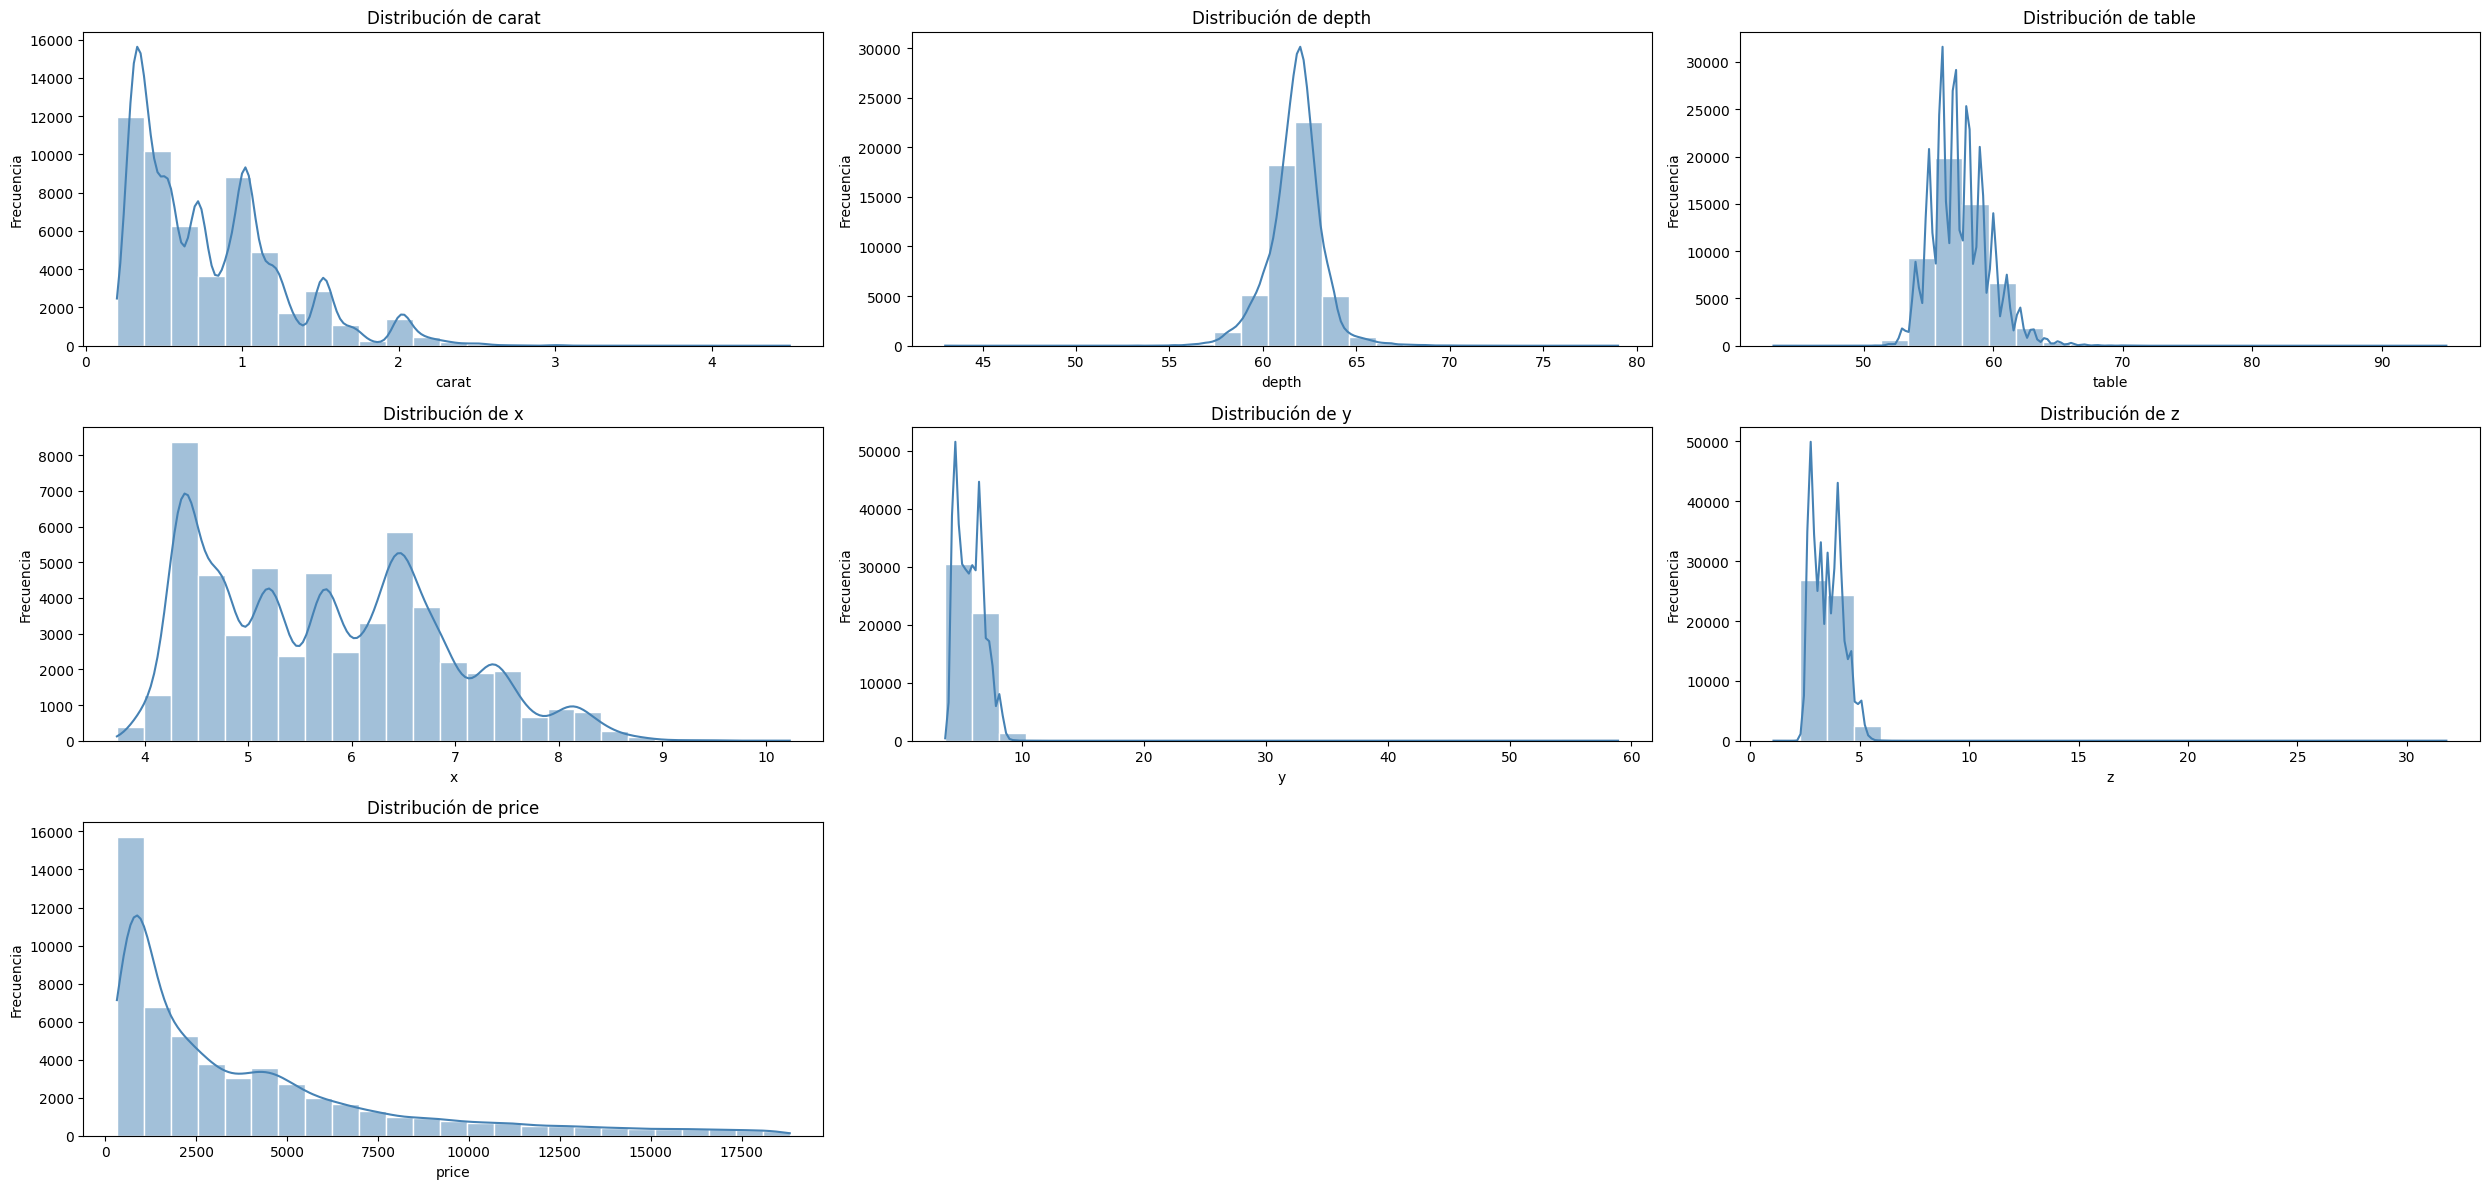

In [ ]:
plt.figure(figsize=(25,12))

for i, col in enumerate(num_cols, 1):
    plt.subplot(3, 3, i)

    sns.histplot(
        data=diamonds_df,
        x=col,
        bins=25,
        kde=True,
        edgecolor='white',
        color='steelblue'
    )

    plt.title(f'Distribución de {col}')
    plt.xlabel(col)
    plt.ylabel('Frecuencia')

plt.tight_layout()
plt.show()

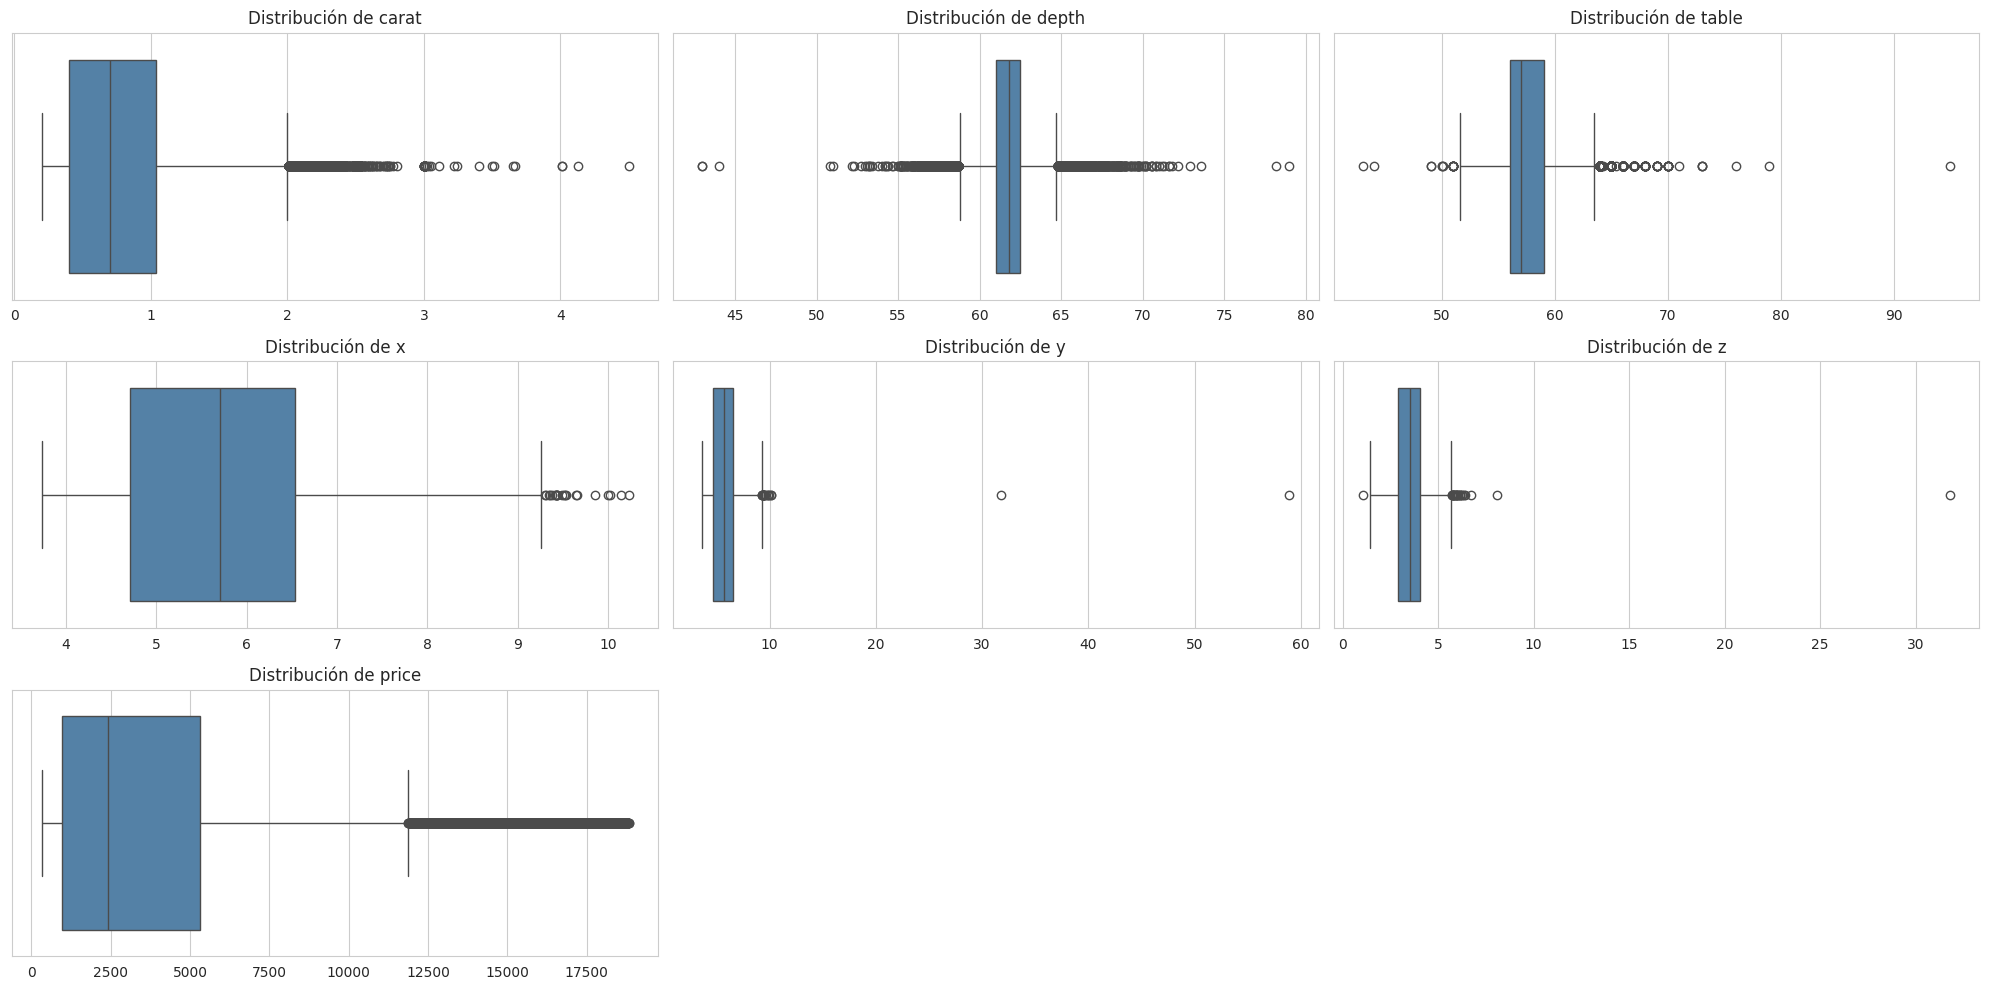

In [ ]:
sns.set_style("whitegrid")

fig, axes = plt.subplots(3, 3, figsize=(20, 10))
axes = axes.ravel()

for i, col in enumerate(num_cols):

    sns.boxplot(
        x=diamonds_df[col],
        ax=axes[i],
        showfliers=True,
        color='steelblue'
    )

    axes[i].set_title(f'Distribución de {col}')
    axes[i].set_xlabel('')

for ax in axes[len(num_cols):]:
    ax.set_visible(False)

plt.tight_layout()
plt.show()

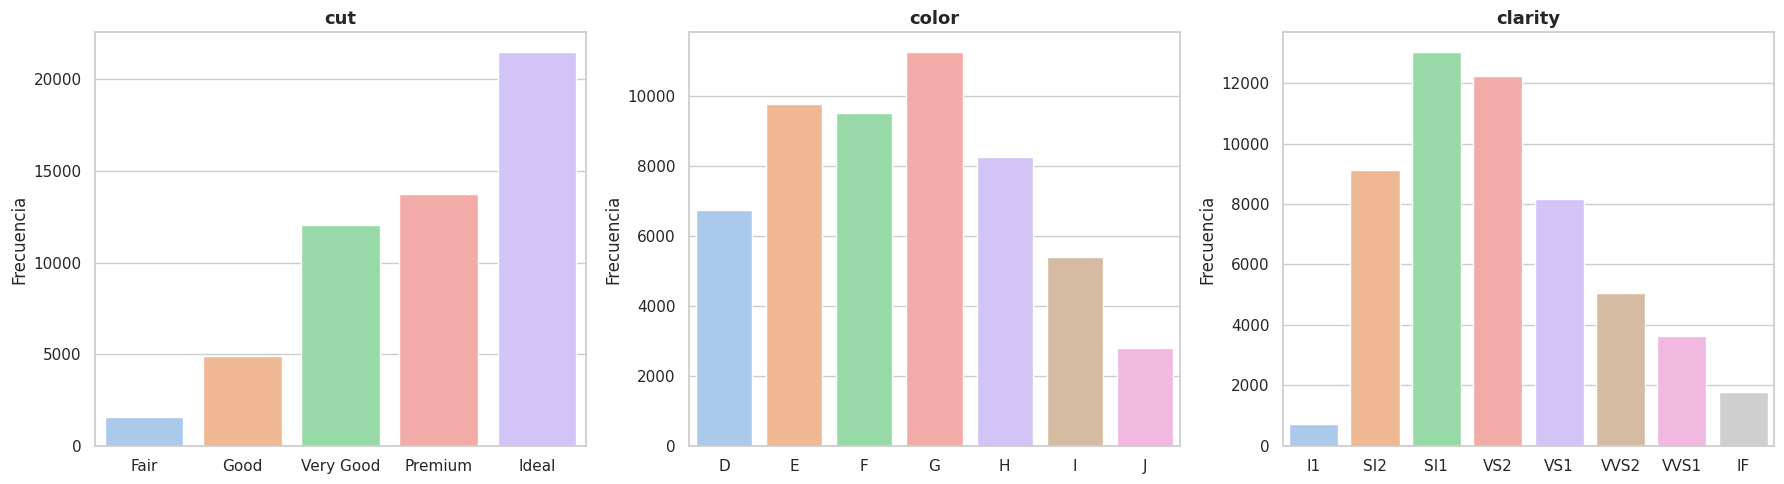

In [ ]:
sns.set_theme(style="whitegrid", palette="pastel")

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for ax, col in zip(axes, cat_cols):

    conteos = diamonds_df[col].value_counts().sort_values(ascending=False)

    sns.barplot(
        x=conteos.index,
        y=conteos.values,
        ax=ax,
        hue=conteos.index,
        legend=False
    )

    ax.set_title(
        f'{col}',
        fontsize=13,
        fontweight='bold'
    )

    ax.set_xlabel('')
    ax.set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

3. Explora relaciones bivariadas en el conjunto de datos mediante gráficos:
* Boxplots que muestren la distribución del precio para cada categoría de color, asegurándose de que las categorías se muestren en el orden de calidad de diamante de mejor a peor: D, E, F, G, H, I, J.
* ¿La tendencia de los precios se comporta como esperabas? Identifica si alguna otra variable podría estar influyendo en la tendencia observada por color y comenta tus observaciones.
* Gráfico de dispersión del precio frente al peso de los diamantes, coloreando los puntos según la categoría de calidad del corte.
* ¿Qué relación se observa entre el peso del diamante y su precio según la calidad del corte?

In [ ]:
#Se asigna orden a las variables categoricas
cut_order = ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']
diamonds_df['cut'] = pd.Categorical(diamonds_df['cut'],categories=cut_order,ordered=True)

color_order = ['D', 'E', 'F', 'G', 'H', 'I', 'J']
diamonds_df['color'] = pd.Categorical(diamonds_df['color'],categories=color_order,ordered=True)

clarity_order = ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']
diamonds_df['clarity'] = pd.Categorical( diamonds_df['clarity'],categories=clarity_order,ordered=True)

In [ ]:
#Se ocultaron  mensaje FutureWarning generado
import warnings

warnings.filterwarnings("ignore", category=FutureWarning)

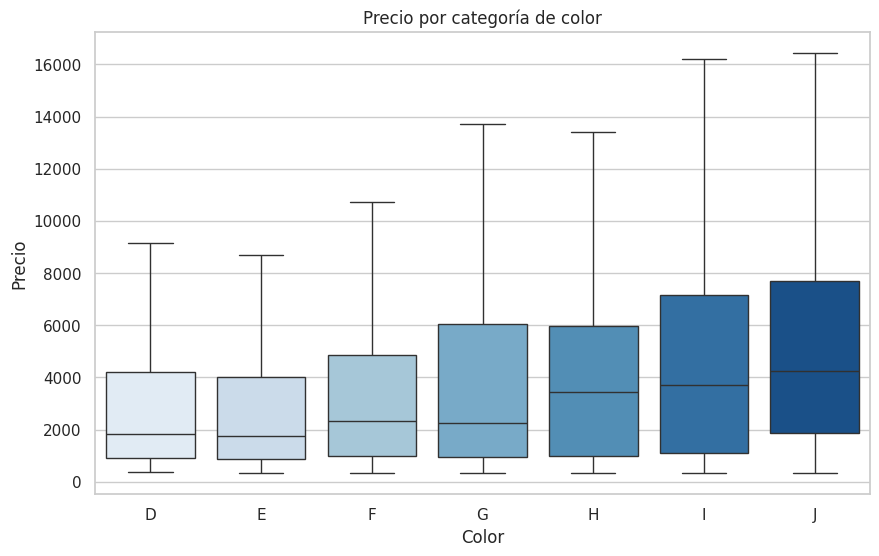

In [ ]:
plt.figure(figsize=(10,6))

sns.boxplot(
    data=diamonds_df,
    x='color',
    y='price',
    hue='color',
    showfliers=False,
    palette='Blues'
)

plt.title('Precio por categoría de color')
plt.xlabel('Color')
plt.ylabel('Precio')
plt.show()

In [ ]:
#Se agrupan los datos por color del diamante y se obtiene la mediana para el precio y el peso del diamante
diamonds_df.groupby('color')[['price','carat']].median()

,price,carat
color,,
D,1842.0,0.53
E,1741.5,0.53
F,2345.0,0.70
G,2242.0,0.70
H,3447.0,0.90
I,3719.0,1.00
J,4234.0,1.11


Revisando la variable carat (peso en quilates) parece influir significativamente en el precio de los diamantes. Al analizar las medianas por categoría de color, se observa que los diamantes de colores H, I y J tienen un mayor peso mediano que los de colores D y E. Por lo tanto, el peso del diamante parece tener una mayor influencia sobre el precio que el color en este conjunto de datos.

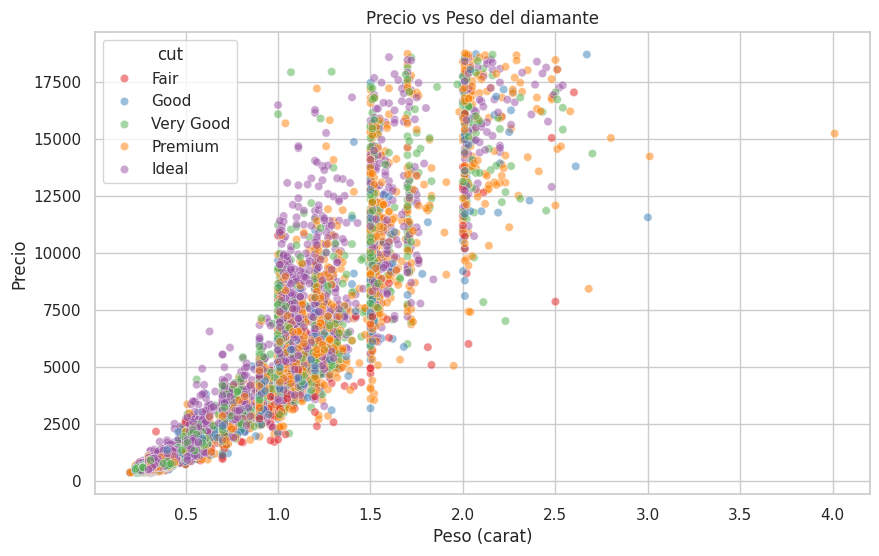

In [ ]:
palette = {
    'Fair': '#e41a1c',
    'Good': '#377eb8',
    'Very Good': '#4daf4a',
    'Premium': '#ff7f00',
    'Ideal': '#984ea3'
}

plt.figure(figsize=(10,6))

sns.scatterplot(
    data=diamonds_df.sample(10000, random_state=42),
    x='carat',
    y='price',
    hue='cut',
    palette = palette,
    alpha=0.5
)

plt.title('Precio vs Peso del diamante')
plt.xlabel('Peso (carat)')
plt.ylabel('Precio')
plt.show()

Se observa una relación positiva entre el peso del diamante y su precio, ya que, en general, los diamantes más pesados tienden a tener precios más altos. Sin embargo, el gráfico de dispersión también muestra que la calidad del corte no determina completamente esta relación. Esto se evidencia en casos donde diamantes con corte Fair presentan precios superiores a otros con corte Premium. Por lo tanto, aunque existe una tendencia general de aumento del precio conforme aumenta el peso del diamante, la relación entre peso y precio varía entre los distintos tipos de corte y no sigue un patrón completamente uniforme.

4. Dibuja un mapa de calor con la matriz de correlación para las variables numéricas del conjunto de datos.
* Identifica los pares de variables cuya correlación sea superior a 0.9 e imprímelos.
* Analiza la correlación entre los predictores (excluyendo `price`), identifica si un único predictor captura información que también está presente en varios otros y elimina los predictores redundantes para simplificar la complejidad de los modelos que construirás más adelante.
* Vuelve a generar el mapa de calor para verificar que ya no queden predictores altamente correlacionados.

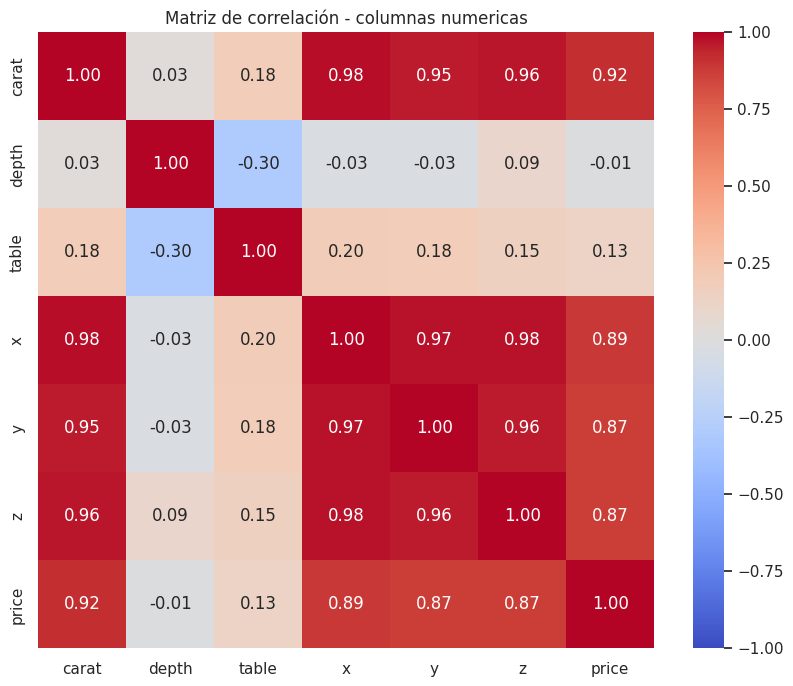

In [ ]:
#heatmap correlacion de Seans
correlacion=diamonds_df[num_cols].corr()
plt.figure(figsize=(10,8))
sns.heatmap(
    correlacion,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    square=True)
plt.title('Matriz de correlación - columnas numericas')
plt.show()


In [ ]:
#Correlacion mayor a 0.9
CorrelacionSinRepetidos=np.triu(np.ones(correlacion.shape, dtype=bool),k=1)
pares=correlacion.where(CorrelacionSinRepetidos).stack()
print(pares[pares.abs()>0.9].sort_values(ascending=False))
#

carat  x        0.978108
x      z        0.975361
       y        0.974799
carat  z        0.961213
y      z        0.956587
carat  y        0.954222
       price    0.921846
dtype: float64


R:

Todos los parametros dimencionales X, Y y Z estan altamente relacionados con entre si y con Carat ya que debido a que es un material con densidad fija el tamaño (Carat) esta directamente relacionado con su volumen por lo que X,Y y Z son redundantes

<Axes: >

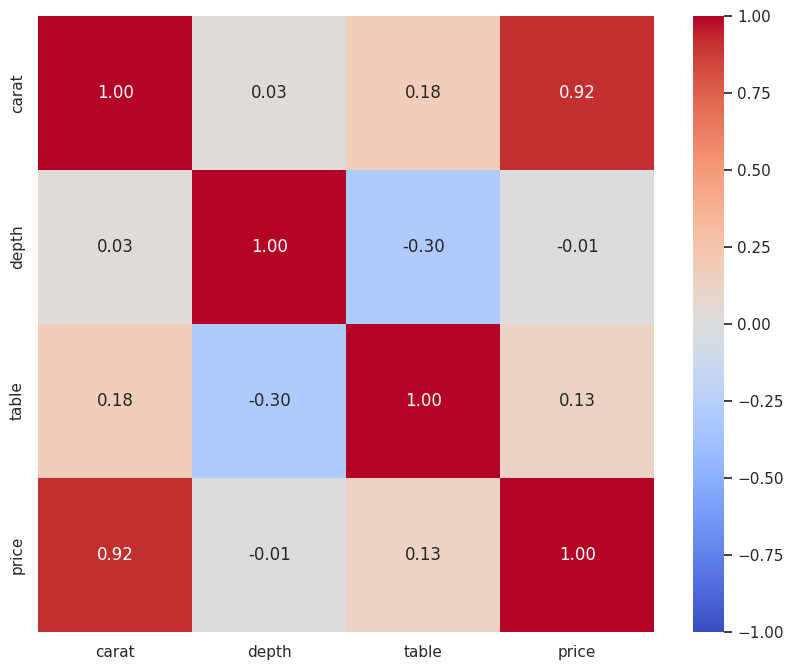

In [ ]:
diamonds_df.drop(columns=['x','y','z'],inplace=True)
num_cols = diamonds_df.select_dtypes(include=['number']).columns.tolist()
cat_cols = diamonds_df.select_dtypes(include=['object', 'category']).columns.tolist()
correlacionnueva= diamonds_df[num_cols].corr()
plt.figure(figsize=(10,8))
sns.heatmap(
    correlacionnueva,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    square=True)

5. Construye un modelo de regresión simple utilizando únicamente la variable predictora que tenga la mayor correlación con `price`. Para ello:
* Asigna esta variable a `X` y `price` a `y` y divide el conjunto de datos en entrenamiento y prueba (80:20), usando `random_state=1` para garantizar reproducibilidad.
* Entrena un modelo con `LinearRegression()` de scikit-learn y evalúalo en el conjunto de prueba utilizando las métricas `RMSE` (Root Mean Squared Error) y `R²` (coeficiente de determinación).
* Añade los valores obtenidos a un dataframe de resultados, que incluya el nombre del modelo (*Baseline*) y una columna para cada métrica.
* Muestra la ecuación de la regresión lineal utilizando el intercepto y el coeficiente asociado al predictor. La ecuación debe tener la forma:
> `price = intercepto + coeficiente × predictor`

In [ ]:
modelo

LinearRegression()

In [ ]:
#Usando solo CARAT como predictor
correlacion_precio=diamonds_df[num_cols].corr()['price'].drop('price')
X= diamonds_df[[correlacion_precio.abs().idxmax()]]
Y= diamonds_df['price']
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=1)

modelo = LinearRegression()
modelo.fit(X_train,Y_train)

Y_prediccion = modelo.predict(X_test)
PruebaRMSE = root_mean_squared_error(Y_test, Y_prediccion)
PruebaR2 = r2_score(Y_test, Y_prediccion)

print(f"RMSE: {PruebaRMSE:,.4f}")
print(f"R2: {PruebaR2:,.4f}")

RMSE: 1,532.4385
R2: 0.8462


In [ ]:
#DATA FRAME RESULTADOS DE MODELO
dfResultados=pd.DataFrame([{'Modelo':'Baseline','RMSE':PruebaRMSE,'R2':PruebaR2}])

dfResultados

,Modelo,RMSE,R2
0,Baseline,1532.43849,0.84618


In [ ]:
predictor= X.columns[0]
print(f"Precio = {modelo.intercept_:,.4f} + {modelo.coef_[0]:,.4f} × {predictor}")

Precio = -2,276.7895 + 7,792.7271 × carat


6. Utiliza todas las variables como predictoras para crear un segundo modelo:
* Haz la asignación correspondiente en `X` y `y` y divide en entrenamiento y prueba usando la misma configuración del ejercicio anterior.
* Prepara un transformador, denominado `preprocessing`, para aplicar escalamiento robusto a los predictores numéricos y codificación ordinal a los categóricos. Asegúrate de respetar el orden correcto de cada categoría, tal como se indica en la descripción de las variables.
* Construye un pipeline que combine el transformador creado con un modelo de regresión lineal.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *Ordinal_Robust*.

In [ ]:
X= diamonds_df.drop(columns=['price'])
Y= diamonds_df['price']
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, test_size=0.2, random_state=1)
cut_orden= ['Fair', 'Good', 'Very Good', 'Premium', 'Ideal']
color_orden= ['J', 'I', 'H', 'G', 'F', 'E', 'D']
clarity_orden= ['I1', 'SI2', 'SI1', 'VS2', 'VS1', 'VVS2', 'VVS1', 'IF']

preprocessing = ColumnTransformer([
    ('num',RobustScaler(),make_column_selector(dtype_include=np.number)),
    ('cat',OrdinalEncoder(categories=[cut_orden,color_orden,clarity_orden]),['cut','color','clarity'])
])

In [ ]:
modelo2

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num', RobustScaler(),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7a75c96ec2f0>),
                                                 ('cat',
                                                  OrdinalEncoder(categories=[['Fair',
                                                                              'Good',
                                                                              'Very '
                                                                              'Good',
                                                                              'Premium',
                                                                              'Ideal'],
                                                                             ['J',
                                                                              'I',
                                                                              'H',
                                                                              'G',
                                                                              'F',
                                                                              'E',
                                                                              'D'],
                                                                             ['I1',
                                                                              'SI2',
                                                                              'SI1',
                                                                              'VS2',
                                                                              'VS1',
                                                                              'VVS2',
                                                                              'VVS1',
                                                                              'IF']]),
                                                  ['cut', 'color',
                                                   'clarity'])])),
                ('linearregression', LinearRegression())])

In [ ]:
modelo2 = make_pipeline(preprocessing,LinearRegression())
modelo2.fit(X_train,Y_train)
Y_prediccion = modelo2.predict(X_test)
PruebaRMSE = root_mean_squared_error(Y_test, Y_prediccion)
PruebaR2 = r2_score(Y_test, Y_prediccion)
print(f"RMSE: {PruebaRMSE:,.4f}")
print(f"R2: {PruebaR2:,.4f}")
dfResultados.loc[len(dfResultados)] = ['Ordinal_Robust',PruebaRMSE,PruebaR2]
dfResultados

RMSE: 1,216.8222
R2: 0.9030


,Modelo,RMSE,R2
0,Baseline,1532.438490,0.846180
1,Ordinal_Robust,1216.822219,0.903016


7. Prepara otro transformador, llamado `preprocessing2`, que aplique escalamiento Min-Max a los predictores numéricos y codificación one-hot a los categóricos, asegurando `drop='first'` para prevenir multicolinealidad en las variables dummies generadas.
* Construye otro pipeline utilizando este nuevo transformador y, a continuación, entrena y evalúa el modelo.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *OHE_MinMax*.

In [ ]:
preprocessing2=ColumnTransformer([
    ('num',MinMaxScaler(),make_column_selector(dtype_include='number')),
    ('cat',OneHotEncoder(drop='first'),['cut','color','clarity'])
])

In [ ]:
modelo_MinMax_OneHot = make_pipeline(preprocessing2,LinearRegression())
modelo_MinMax_OneHot.fit(X_train,Y_train)
Y_prediccion = modelo_MinMax_OneHot.predict(X_test)
PruebaRMSE = root_mean_squared_error(Y_test, Y_prediccion)
PruebaR2 = r2_score(Y_test, Y_prediccion)
print(f"RMSE: {PruebaRMSE:,.4f}")
print(f"R2: {PruebaR2:,.4f}")
dfResultados.loc[len(dfResultados)] = ['OHE_MinMax',PruebaRMSE,PruebaR2]
dfResultados

RMSE: 1,142.5191
R2: 0.9145


,Modelo,RMSE,R2
0,Baseline,1532.438490,0.846180
1,Ordinal_Robust,1216.822219,0.903016
2,OHE_MinMax,1142.519131,0.914499


8. Modifica el pipeline anterior para emplear regresión polinomial de segundo grado y evalúa si esto mejora el ajuste del modelo.
* Añade los valores de las métricas obtenidas al dataframe de resultados, utilizando como nombre del modelo *PolynomialDegree2*.

In [ ]:
modelo_poly = make_pipeline(
    preprocessing2,
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)
modelo_poly.fit(X_train, Y_train)

Y_pred_poly = modelo_poly.predict(X_test)
rmse_poly = root_mean_squared_error(Y_test, Y_pred_poly)
r2_poly = r2_score(Y_test, Y_pred_poly)

r2_poly_train = r2_score(Y_train, modelo_poly.predict(X_train))

print(f"RMSE (prueba): {rmse_poly:,.4f}")
print(f"R2 (prueba):   {r2_poly:,.4f}")
print(f"R2 (entrenamiento): {r2_poly_train:,.4f}")

dfResultados.loc[len(dfResultados)] = ['PolynomialDegree2', rmse_poly, r2_poly]
dfResultados

RMSE (prueba): 749.0364
R2 (prueba):   0.9633
R2 (entrenamiento): 0.9641


,Modelo,RMSE,R2
0,Baseline,1532.438490,0.846180
1,Ordinal_Robust,1216.822219,0.903016
2,OHE_MinMax,1142.519131,0.914499
3,PolynomialDegree2,749.036382,0.963250


**Conclusión:** Al realizar este último modelo y obtener los resultados se evidencia que este es el que mejor se ajusta a los datos y que el comportamiento del precio en relación a los demás factores de los diamantes no puede ser representado de manera precia por un modelo lineal (Una línea recta) sino que es mejor representado por una curva (Ecuación de segundo grado).

9. Ordena el dataframe de resultados según el `R²`, de manera que el modelo con mejor desempeño aparezca primero.
* Para dicho modelo, crea un gráfico de dispersión de los valores reales frente a los predichos, e incluye una línea diagonal de referencia para indicar una predicción perfecta.

,Modelo,RMSE,R2
0,PolynomialDegree2,749.036382,0.963250
1,OHE_MinMax,1142.519131,0.914499
2,Ordinal_Robust,1216.822219,0.903016
3,Baseline,1532.438490,0.846180


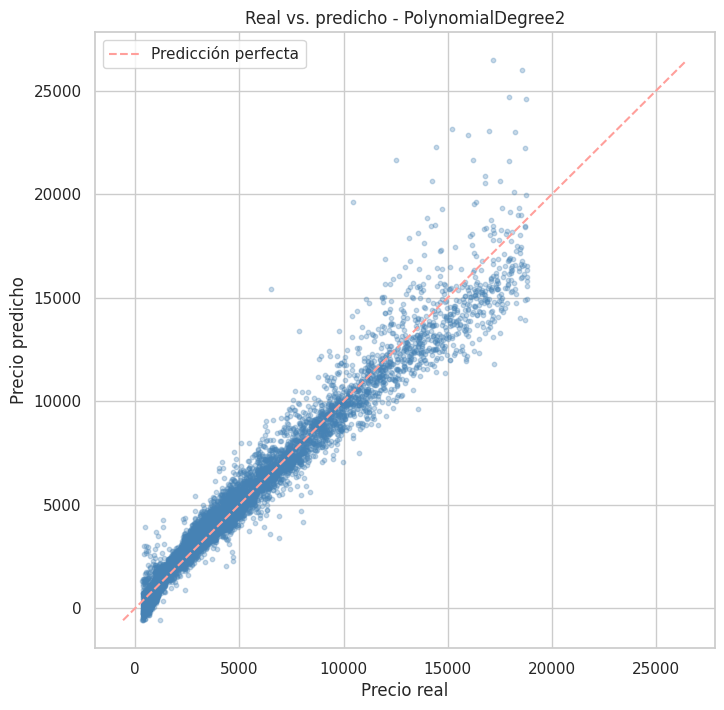

Predicciones negativas: 198 de 10755


In [ ]:

dfResultados = dfResultados.sort_values('R2', ascending=False).reset_index(drop=True)
display(dfResultados)


modelos = {
    'Ordinal_Robust': modelo2,
    'OHE_MinMax': modelo_MinMax_OneHot,
    'PolynomialDegree2': modelo_poly
}
mejor_nombre = dfResultados.loc[0, 'Modelo']
mejor_modelo = modelos[mejor_nombre]
Y_pred_mejor = mejor_modelo.predict(X_test)


plt.figure(figsize=(8, 8))
plt.scatter(Y_test, Y_pred_mejor, alpha=0.3, s=10, color='steelblue')
lim = [min(Y_test.min(), Y_pred_mejor.min()), max(Y_test.max(), Y_pred_mejor.max())]
plt.plot(lim, lim, 'r--', label='Predicción perfecta')
plt.xlabel('Precio real')
plt.ylabel('Precio predicho')
plt.title(f'Real vs. predicho - {mejor_nombre}')
plt.legend()
plt.show()

print(f"Predicciones negativas: {(Y_pred_mejor < 0).sum()} de {len(Y_pred_mejor)}")

10. Muestra la representación gráfica del pipeline para ubicar la posición de cada elemento dentro del flujo del modelo.
* Obtén los nombres de todas las columnas después del preprocesamiento (numéricas y dummies de categóricas).
* Extrae los nombres de las columnas polinómicas.
* Recupera los coeficientes y el intercepto del modelo de regresión lineal.
* Ordena los coeficientes por su valor absoluto para mostrar los 10 más importantes y da conclusiones sobre cómo los distintos factores influyen en el precio.

In [ ]:
from sklearn import set_config
set_config(display='diagram')
display(modelo_poly)

Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('num', MinMaxScaler(),
                                                  <sklearn.compose._column_transformer.make_column_selector object at 0x7a75c96f7b10>),
                                                 ('cat',
                                                  OneHotEncoder(drop='first'),
                                                  ['cut', 'color',
                                                   'clarity'])])),
                ('polynomialfeatures', PolynomialFeatures(include_bias=False)),
                ('linearregression', LinearRegression())])

In [ ]:
prep = modelo_poly.named_steps['columntransformer']
poly = modelo_poly.named_steps['polynomialfeatures']
lin = modelo_poly.named_steps['linearregression']

nombres_prep = prep.get_feature_names_out()
print(f"Columnas tras el preprocesamiento: {len(nombres_prep)}")
print(list(nombres_prep))

nombres_poly = poly.get_feature_names_out(nombres_prep)
print(f"\nColumnas tras PolynomialFeatures: {len(nombres_poly)}")

print(f"\nIntercepto: {lin.intercept_:,.4f}")
coef_df = pd.DataFrame({'variable': nombres_poly, 'coeficiente': lin.coef_})
coef_df['abs_coef'] = coef_df['coeficiente'].abs()

top10 = coef_df.sort_values('abs_coef', ascending=False).head(10).reset_index(drop=True)
top10

Columnas tras el preprocesamiento: 20
['num__carat', 'num__depth', 'num__table', 'cat__cut_Good', 'cat__cut_Ideal', 'cat__cut_Premium', 'cat__cut_Very Good', 'cat__color_E', 'cat__color_F', 'cat__color_G', 'cat__color_H', 'cat__color_I', 'cat__color_J', 'cat__clarity_IF', 'cat__clarity_SI1', 'cat__clarity_SI2', 'cat__clarity_VS1', 'cat__clarity_VS2', 'cat__clarity_VVS1', 'cat__clarity_VVS2']

Columnas tras PolynomialFeatures: 230

Intercepto: -909.4924


,variable,coeficiente,abs_coef
0,num__carat^2,55139.394904,55139.394904
1,num__carat cat__clarity_IF,49901.020444,49901.020444
2,num__carat cat__clarity_VVS1,46676.274624,46676.274624
3,num__carat cat__clarity_VVS2,44778.777980,44778.777980
4,num__carat cat__clarity_VS1,40030.561597,40030.561597
5,num__carat cat__clarity_VS2,37092.171153,37092.171153
6,num__carat cat__clarity_SI1,31996.333902,31996.333902
7,num__carat cat__clarity_SI2,24370.410622,24370.410622
8,num__carat cat__color_J,-20648.946158,20648.946158
9,num__carat cat__color_I,-14266.529952,14266.529952


**Conclusión:** Al obtener los resultados de los coeficientes se evidencia que el kilataje (Carat de grado 2 y las interacciones con clarity) es el factor más influyente para predecir el precio pues se encuentra en todas las variables identificadas como relevantes en el modelo. De igual forma, en segundo lugar se encuentra clarity como factor relevante (Siendo las más relevante VVS1, VVS2 y VS2) y color como tercer factor relevante considerando que cuando se incluyen ciertos tipos de color el coeficiente es negativo por lo que el precio disminuye.

---

**Declaración de uso de IA**

*   Anthropic. (2026). *CLAUDE (Opus 5.5)* [Modelo de lenguaje grande], utilizado para depuración. https://claude.ai/